# TP : Comptage des mots Comparaison de trois méthodes

## 1. Introduction

L'objectif de ce TP est de comparer trois approches permettant de compter
le nombre d'occurrences de chaque mot dans un fichier texte.

Les trois méthodes étudiées sont :

1. Python simple : comptage séquentiel à l'aide d'un dictionnaire.
2. Pseudo-MapReduce Python : simulation des étapes Map, Shuffle et Reduce.
3. Hadoop MapReduce : utilisation du framework Hadoop pour effectuer
   le comptage des mots.

Nous allons mesurer les temps d'exécution de ces trois méthodes sur
des fichiers de différentes tailles, vérifier que les résultats obtenus
sont identiques et analyser leurs performances.

## 2. Environnement et outils utilisés

- Système d'exploitation : Ubuntu Linux.
- Langage : Python 3.10.12.
- Environnement Python : environnement virtuel `.venv`.
- Outil de développement : Jupyter Notebook.
- Framework distribué prévu : Apache Hadoop.

## 3. Génération du fichier de test

Nous créons un fichier texte nommé `mots.txt` contenant un mot par ligne.

Le fichier contient volontairement des répétitions afin de pouvoir
mesurer le nombre d'occurrences de chaque mot.

Ce fichier servira de référence pour tester les trois méthodes.

In [1]:
from pathlib import Path
from collections import Counter

# Définition du fichier de test
fichier_mots = Path("mots.txt")

# Liste de mots avec des répétitions
mots = [
    "chat", "chien", "chat", "voiture", "chat",
    "arbre", "chien", "fleur", "chat", "voiture",
    "soleil", "arbre", "chat", "chien", "fleur",
    "livre", "chat", "montagne", "chien", "soleil"
]

# Création du fichier : un mot par ligne
with open(fichier_mots, "w", encoding="utf-8") as f:
    for mot in mots:
        f.write(mot + "\n")

print("Fichier créé :", fichier_mots.resolve())
print("Nombre de lignes :", len(mots))
print("Contenu du fichier :")
print(fichier_mots.read_text(encoding="utf-8"))

Fichier créé : /home/ssl/Documents/5A/S9/BD/TP_Comptage_Mots/mots.txt
Nombre de lignes : 20
Contenu du fichier :
chat
chien
chat
voiture
chat
arbre
chien
fleur
chat
voiture
soleil
arbre
chat
chien
fleur
livre
chat
montagne
chien
soleil



## 4. Méthode 1 : Python simple

### Principe

La première méthode utilise un dictionnaire Python pour compter
les occurrences de chaque mot dans le fichier.

Le programme lit le fichier, récupère tous les mots avec la méthode
`split()`, puis parcourt les mots un par un.

Pour chaque mot, le compteur correspondant est incrémenté de 1.
Les résultats sont ensuite triés par ordre décroissant du nombre
d'occurrences.

Cette méthode est séquentielle : les mots sont traités les uns
après les autres, sans parallélisation.

In [2]:
def compter_occurrences(fichier):
    """
    Compte les occurrences de chaque mot dans un fichier texte.

    Paramètre :
        fichier : chemin du fichier à analyser.

    Retour :
        Un dictionnaire contenant chaque mot et son nombre d'occurrences.
    """
    with open(fichier, "r", encoding="utf-8") as f:
        mots = f.read().split()

    compteur = {}

    for mot in mots:
        compteur[mot] = compteur.get(mot, 0) + 1

    return compteur


# Exécution de la méthode 1
resultats_python = compter_occurrences(fichier_mots)

# Affichage des résultats par ordre décroissant
for mot, nombre in sorted(
    resultats_python.items(),
    key=lambda element: element[1],
    reverse=True
):
    print(f"{mot} : {nombre}")

chat : 6
chien : 4
voiture : 2
arbre : 2
fleur : 2
soleil : 2
livre : 1
montagne : 1


In [3]:
# Vérification du nombre total de mots comptabilisés
total_mots = sum(resultats_python.values())

print("Nombre total de mots :", total_mots)
print("Nombre de mots différents :", len(resultats_python))

assert total_mots == 20, "Erreur : le total doit être égal à 20."

print("Vérification réussie : les 20 mots ont été comptabilisés.")

Nombre total de mots : 20
Nombre de mots différents : 8
Vérification réussie : les 20 mots ont été comptabilisés.


### Mesure du temps d'exécution

Nous utilisons le module `time` pour mesurer le temps nécessaire
à l'exécution de la méthode Python simple.

La mesure inclut la lecture du fichier et le comptage des mots.

In [4]:
import time

debut = time.perf_counter()

resultats_python = compter_occurrences(fichier_mots)

fin = time.perf_counter()

temps_python = fin - debut

print(f"Temps d'exécution : {temps_python:.6f} seconde(s)")

Temps d'exécution : 0.000340 seconde(s)


## 5. Méthode 2 : Pseudo-MapReduce Python

### Principe

Cette deuxième méthode reproduit localement les trois étapes du modèle
MapReduce : Map, Shuffle et Reduce.

- Map : chaque mot est transformé en une paire (mot, 1).
- Shuffle : les valeurs associées à chaque mot sont regroupées.
- Reduce : les valeurs de chaque groupe sont additionnées pour obtenir
  le nombre total d'occurrences.

Contrairement à Hadoop, cette implémentation s'exécute entièrement
sur une seule machine. Elle permet néanmoins de comprendre
l'organisation du traitement MapReduce.

In [5]:
from collections import defaultdict


def mapper(ligne):
    """
    Transforme chaque mot d'une ligne en une paire (mot, 1).
    """
    mots = ligne.strip().split()
    return [(mot, 1) for mot in mots]


def shuffle(mapped_data):
    """
    Regroupe les valeurs associées à chaque mot.
    """
    grouped = defaultdict(list)

    for mot, valeur in mapped_data:
        grouped[mot].append(valeur)

    return grouped


def reducer(grouped_data):
    """
    Additionne les valeurs associées à chaque mot.
    """
    reduced = {}

    for mot, valeurs in grouped_data.items():
        reduced[mot] = sum(valeurs)

    return reduced


# Exécution de la méthode 2
mapped = []

with open(fichier_mots, "r", encoding="utf-8") as f:
    for ligne in f:
        mapped.extend(mapper(ligne))

grouped = shuffle(mapped)
resultats_mapreduce = reducer(grouped)

# Affichage des résultats
for mot, nombre in sorted(
    resultats_mapreduce.items(),
    key=lambda element: element[1],
    reverse=True
):
    print(f"{mot} : {nombre}")

chat : 6
chien : 4
voiture : 2
arbre : 2
fleur : 2
soleil : 2
livre : 1
montagne : 1


In [6]:
# Comparaison des résultats des deux méthodes
assert resultats_python == resultats_mapreduce, (
    "Erreur : les deux méthodes donnent des résultats différents."
)

print("Vérification réussie : les deux méthodes donnent les mêmes résultats.")

print("Total des mots :", sum(resultats_mapreduce.values()))
print("Nombre de mots différents :", len(resultats_mapreduce))

Vérification réussie : les deux méthodes donnent les mêmes résultats.
Total des mots : 20
Nombre de mots différents : 8


In [7]:
debut = time.perf_counter()

mapped = []

with open(fichier_mots, "r", encoding="utf-8") as f:
    for ligne in f:
        mapped.extend(mapper(ligne))

grouped = shuffle(mapped)
resultats_mapreduce = reducer(grouped)

fin = time.perf_counter()

temps_mapreduce = fin - debut

print(f"Temps d'exécution : {temps_mapreduce:.6f} seconde(s)")

Temps d'exécution : 0.000383 seconde(s)


## 6. Comparaison des performances sur différentes tailles de fichiers

### Objectif

Nous cherchons à comparer les performances des deux implémentations
Python en faisant varier la taille des fichiers d'entrée.

Nous générons plusieurs fichiers en dupliquant le contenu du fichier
initial `mots.txt`. Chaque ligne contient un mot.

Pour chaque fichier, nous exécutons les deux méthodes :
- Python simple ;
- Pseudo-MapReduce Python.

Nous mesurons leur temps d'exécution et vérifions que les résultats
obtenus sont identiques.

Les temps sont mesurés plusieurs fois et nous retenons la médiane
afin de limiter l'influence des variations ponctuelles du système.

In [29]:
from pathlib import Path

# ============================================================
# 1. CONFIGURATION
# ============================================================

fichier_source = Path("mots.txt")
dossier_tests = Path("fichiers_test")
dossier_tests.mkdir(parents=True, exist_ok=True)

# Lire le fichier source
contenu = fichier_source.read_bytes()

if not contenu:
    raise ValueError("Le fichier mots.txt est vide.")

# Compter les lignes du fichier source
with fichier_source.open("rb") as f:
    lignes_source = f.readlines()

if not lignes_source:
    raise ValueError("Le fichier source ne contient aucune ligne.")

print(f"Fichier source : {fichier_source}")
print(f"Nombre de lignes initial : {len(lignes_source)}")


# ============================================================
# 2. DÉFINIR LES FICHIERS À GÉNÉRER
# ============================================================

tailles_fichiers = {
    "100_lignes": ("lignes", 100),
    "1000_lignes": ("lignes", 1_000),
    "10000_lignes": ("lignes", 10_000),
    "100000_lignes": ("lignes", 100_000),
    "1_Mo": ("taille", 1_000_000),
    "10_Mo": ("taille", 10_000_000),
    "100_Mo": ("taille", 100_000_000),
    "500_Mo": ("taille", 500_000_000),
    "1_Go": ("taille", 1_000_000_000),
}


# ============================================================
# 3. GÉNÉRATION D'UN FICHIER AVEC UN NOMBRE DE LIGNES FIXE
# ============================================================

def generer_fichier_lignes(nombre_lignes, destination):
    with destination.open("wb") as sortie:
        lignes_ecrites = 0

        while lignes_ecrites < nombre_lignes:
            for ligne in lignes_source:
                if lignes_ecrites >= nombre_lignes:
                    break

                sortie.write(ligne)
                lignes_ecrites += 1


# ============================================================
# 4. GÉNÉRATION D'UN FICHIER AVEC UNE TAILLE FIXE
# ============================================================

def generer_fichier_taille(taille_cible, destination):
    taille_bloc = len(contenu)

    repetitions = taille_cible // taille_bloc
    reste = taille_cible % taille_bloc

    with destination.open("wb") as sortie:
        # Écriture par blocs pour limiter les opérations d'écriture
        bloc_repetitions = contenu * 1000

        while repetitions >= 1000:
            sortie.write(bloc_repetitions)
            repetitions -= 1000

        if repetitions > 0:
            sortie.write(contenu * repetitions)

        if reste > 0:
            sortie.write(contenu[:reste])


# ============================================================
# 5. GÉNÉRATION DE TOUS LES FICHIERS
# ============================================================

fichiers_generes = {}

for nom, (type_generation, valeur) in tailles_fichiers.items():

    fichier_test = dossier_tests / f"mots_{nom}.txt"

    if type_generation == "lignes":
        generer_fichier_lignes(valeur, fichier_test)
    else:
        generer_fichier_taille(valeur, fichier_test)

    fichiers_generes[nom] = fichier_test

    taille_octets = fichier_test.stat().st_size

    with fichier_test.open("rb") as f:
        nombre_lignes_reel = sum(1 for _ in f)

    print(
    f"{nom:15} | "
    f"Lignes : {nombre_lignes_reel:>10,} | "
    f"Taille : {taille_octets / 1024:>12,.2f} Ko"
)

print("\nTous les fichiers ont été générés.")

Fichier source : mots.txt
Nombre de lignes initial : 20
100_lignes      | Lignes :        100 | Taille :         0.60 Ko
1000_lignes     | Lignes :      1,000 | Taille :         6.01 Ko
10000_lignes    | Lignes :     10,000 | Taille :        60.06 Ko
100000_lignes   | Lignes :    100,000 | Taille :       600.59 Ko
1_Mo            | Lignes :    162,602 | Taille :       976.56 Ko
10_Mo           | Lignes :  1,626,017 | Taille :     9,765.62 Ko
100_Mo          | Lignes : 16,260,163 | Taille :    97,656.25 Ko
500_Mo          | Lignes : 81,300,814 | Taille :   488,281.25 Ko
1_Go            | Lignes : 162,601,627 | Taille :   976,562.50 Ko

Tous les fichiers ont été générés.


In [30]:
import time
import statistics
import pandas as pd
from collections import defaultdict


# ============================================================
# MÉTHODE 1 : PYTHON SIMPLE
# ============================================================

def compter_python(fichier):
    with open(fichier, "r", encoding="utf-8") as f:
        mots = f.read().split()

    compteur = {}

    for mot in mots:
        compteur[mot] = compteur.get(mot, 0) + 1

    return compteur


# Version progressive : lecture ligne par ligne
def compter_python_progressif(fichier):
    compteur = {}

    with open(fichier, "r", encoding="utf-8") as f:
        for ligne in f:
            for mot in ligne.split():
                compteur[mot] = compteur.get(mot, 0) + 1

    return compteur


# ============================================================
# MÉTHODE 2 : PSEUDO-MAPREDUCE
# ============================================================

def mapper(ligne):
    mots = ligne.strip().split()
    return [(mot, 1) for mot in mots]


def shuffle(mapped_data):
    grouped = defaultdict(list)

    for mot, valeur in mapped_data:
        grouped[mot].append(valeur)

    return grouped


def reducer(grouped_data):
    return {
        mot: sum(valeurs)
        for mot, valeurs in grouped_data.items()
    }


def compter_pseudo_mapreduce(fichier):
    mapped = []

    with open(fichier, "r", encoding="utf-8") as f:
        for ligne in f:
            mapped.extend(mapper(ligne))

    grouped = shuffle(mapped)

    return reducer(grouped)


# Variante économe en mémoire
def compter_mapreduce_econome(fichier):
    compteur = defaultdict(int)

    with open(fichier, "r", encoding="utf-8") as f:
        for ligne in f:
            for mot, valeur in mapper(ligne):
                compteur[mot] += valeur

    return dict(compteur)


# ============================================================
# MESURE DU TEMPS D'EXÉCUTION
# ============================================================

def mesurer_temps(fonction, fichier, repetitions=3):
    durees = []

    for _ in range(repetitions):
        debut = time.perf_counter()
        fonction(fichier)
        fin = time.perf_counter()

        durees.append(fin - debut)

    return statistics.median(durees)


# ============================================================
# COMPARAISON DES MÉTHODES
# ============================================================

resultats_benchmarks = []

for nom, fichier in fichiers_generes.items():

    taille_octets = fichier.stat().st_size
    taille_ko = taille_octets / 1024

    print(f"\nTest du fichier : {nom}")
    print(f"Taille : {taille_ko:,.2f} Ko")

    # Choisir les méthodes selon la taille du fichier
    if taille_octets <= 10_000_000:

        fonction_simple = compter_python
        fonction_mapreduce = compter_pseudo_mapreduce

        nom_simple = "Python simple"
        nom_mapreduce = "Pseudo-MapReduce"

    else:

        fonction_simple = compter_python_progressif
        fonction_mapreduce = compter_mapreduce_econome

        nom_simple = "Python progressif"
        nom_mapreduce = "MapReduce économe"

    # Mesurer les temps
    temps_simple = mesurer_temps(
        fonction_simple,
        fichier
    )

    temps_mapreduce = mesurer_temps(
        fonction_mapreduce,
        fichier
    )

    # Vérifier l'égalité des résultats
    resultat_simple = fonction_simple(fichier)
    resultat_mapreduce = fonction_mapreduce(fichier)

    assert resultat_simple == resultat_mapreduce, (
        f"Résultats différents pour {nom}"
    )

    print("Vérification des résultats : OK")

    # Compter les lignes réellement présentes
    with fichier.open("rb") as f:
        nombre_lignes = sum(1 for _ in f)

    # Ajouter les résultats au tableau
    resultats_benchmarks.append({
        "Fichier": nom,
        "Nombre de lignes": nombre_lignes,
        "Taille (Ko)": round(taille_ko, 2),
        "Méthode Python": nom_simple,
        "Python (s)": round(temps_simple, 6),
        "Méthode MapReduce": nom_mapreduce,
        "MapReduce (s)": round(temps_mapreduce, 6)
    })


# ============================================================
# AFFICHAGE DU TABLEAU FINAL
# ============================================================

df_benchmarks = pd.DataFrame(resultats_benchmarks)

print("\nTous les tests sont réussis.")

display(df_benchmarks)


Test du fichier : 100_lignes
Taille : 0.60 Ko
Vérification des résultats : OK

Test du fichier : 1000_lignes
Taille : 6.01 Ko
Vérification des résultats : OK

Test du fichier : 10000_lignes
Taille : 60.06 Ko
Vérification des résultats : OK

Test du fichier : 100000_lignes
Taille : 600.59 Ko
Vérification des résultats : OK

Test du fichier : 1_Mo
Taille : 976.56 Ko
Vérification des résultats : OK

Test du fichier : 10_Mo
Taille : 9,765.62 Ko
Vérification des résultats : OK

Test du fichier : 100_Mo
Taille : 97,656.25 Ko
Vérification des résultats : OK

Test du fichier : 500_Mo
Taille : 488,281.25 Ko
Vérification des résultats : OK

Test du fichier : 1_Go
Taille : 976,562.50 Ko
Vérification des résultats : OK

Tous les tests sont réussis.


,Fichier,Nombre de lignes,Taille (Ko),Méthode Python,Python (s),Méthode MapReduce,MapReduce (s)
0,100_lignes,100,0.60,Python simple,0.000068,Pseudo-MapReduce,0.000100
1,1000_lignes,1000,6.01,Python simple,0.000202,Pseudo-MapReduce,0.000506
2,10000_lignes,10000,60.06,Python simple,0.001247,Pseudo-MapReduce,0.005297
3,100000_lignes,100000,600.59,Python simple,0.012819,Pseudo-MapReduce,0.047254
4,1_Mo,162602,976.56,Python simple,0.019775,Pseudo-MapReduce,0.076933
5,10_Mo,1626017,9765.62,Python simple,0.221388,Pseudo-MapReduce,0.836269
6,100_Mo,16260163,97656.25,Python progressif,3.406362,MapReduce économe,9.310586
7,500_Mo,81300814,488281.25,Python progressif,19.718671,MapReduce économe,46.454183
8,1_Go,162601627,976562.50,Python progressif,43.195553,MapReduce économe,89.884070


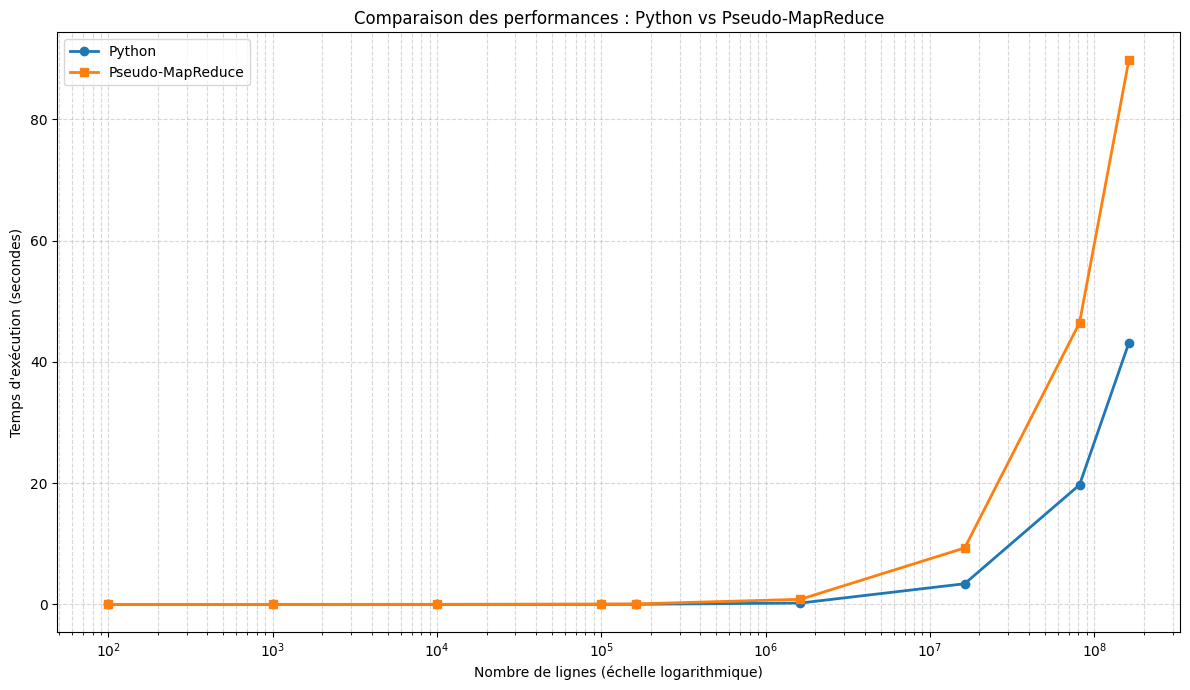

In [33]:
import matplotlib.pyplot as plt

# ============================================================
# GRAPHIQUE : COMPARAISON DES PERFORMANCES
# ============================================================

plt.figure(figsize=(12, 7))

# Python
plt.plot(
    df_benchmarks["Nombre de lignes"],
    df_benchmarks["Python (s)"],
    marker="o",
    linewidth=2,
    label="Python"
)

# Pseudo-MapReduce
plt.plot(
    df_benchmarks["Nombre de lignes"],
    df_benchmarks["MapReduce (s)"],
    marker="s",
    linewidth=2,
    label="Pseudo-MapReduce"
)

# Échelle logarithmique pour l'axe des x
plt.xscale("log")

plt.xlabel("Nombre de lignes (échelle logarithmique)")
plt.ylabel("Temps d'exécution (secondes)")

plt.title("Comparaison des performances : Python vs Pseudo-MapReduce")

plt.legend()
plt.grid(True, which="both", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()